In [ ]:



!pip install -q pandas numpy scikit-learn matplotlib seaborn xgboost imbalanced-learn shap joblib

print("CREDORA ML environment setup completed!")


CREDORA ML environment setup completed!


In [ ]:

# CREDORA - Import Libraries

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# =====================================================
# CREDORA | DATASET INSPECTION
# =====================================================

import pandas as pd
import os

# Load the uploaded datasets
ulb = pd.read_csv('/content/creditcard.csv')
sparkov = pd.read_csv('/content/fraudTrain.csv')
paysim = pd.read_csv('/content/PS_20174392719_1491204439457_log.csv')

datasets = {
    "ULB CREDIT CARD": ulb,
    "SPARKOV": sparkov,
    "PAYSIM": paysim
}

# Inspect each dataset
for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"DATASET: {name}")
    print("=" * 70)

    print("\nNumber of rows:", len(df))
    print("Number of columns:", len(df.columns))

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isnull().sum().sum())

    print("\nFirst 5 records:")
    display(df.head())



DATASET: ULB CREDIT CARD

Number of rows: 284807
Number of columns: 31

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing values:
0

First 5 records:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



DATASET: SPARKOV

Number of rows: 1296675
Number of columns: 23

Column names:
['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']

Missing values:
0

First 5 records:


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0



DATASET: PAYSIM

Number of rows: 6362620
Number of columns: 11

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Missing values:
0

First 5 records:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0



ULB FRAUD ANALYSIS

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

Fraud records: 492
Legitimate records: 284315


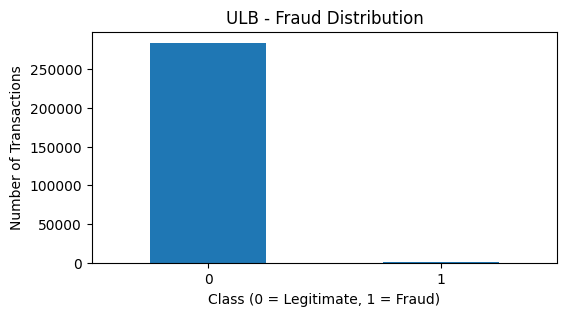


SPARKOV FRAUD ANALYSIS

Transaction counts:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Transaction percentages:
is_fraud
0    99.4211
1     0.5789
Name: proportion, dtype: float64

Fraud records: 7506
Legitimate records: 1289169


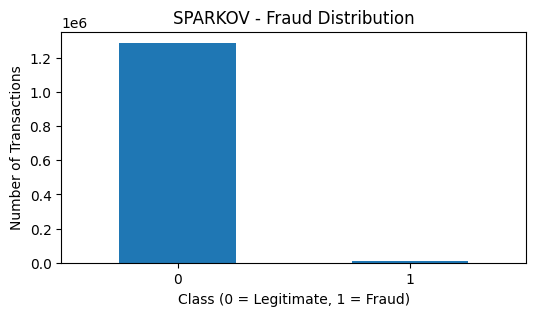


PAYSIM FRAUD ANALYSIS

Transaction counts:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Transaction percentages:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

Fraud records: 8213
Legitimate records: 6354407


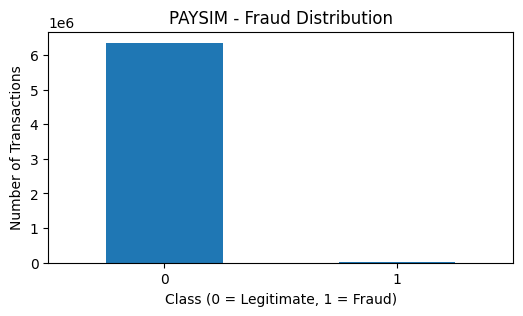

In [ ]:

# =====================================================
# CREDORA | FRAUD DISTRIBUTION ANALYSIS
# =====================================================

datasets = {
    "ULB": (ulb, "Class"),
    "SPARKOV": (sparkov, "is_fraud"),
    "PAYSIM": (paysim, "isFraud")
}

for name, (df, target) in datasets.items():

    print("\n" + "=" * 60)
    print(f"{name} FRAUD ANALYSIS")
    print("=" * 60)

    if target not in df.columns:
        print(f"Target column '{target}' not found!")
        print("Available columns:", df.columns.tolist())
        continue

    counts = df[target].value_counts().sort_index()

    print("\nTransaction counts:")
    print(counts)

    print("\nTransaction percentages:")
    print((df[target].value_counts(normalize=True) * 100).round(4))

    print("\nFraud records:", int((df[target] == 1).sum()))
    print("Legitimate records:", int((df[target] == 0).sum()))

    # Visualisation
    counts.plot(kind="bar", figsize=(6, 3))
    plt.title(f"{name} - Fraud Distribution")
    plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
    plt.ylabel("Number of Transactions")
    plt.xticks(rotation=0)
    plt.show()


In [ ]:

# ==========================================================
# CREDORA | DATA QUALITY ASSESSMENT
# ==========================================================

datasets = {
    "ULB": ulb,
    "SPARKOV": sparkov,
    "PAYSIM": paysim
}

for name, df in datasets.items():

    print("\n" + "=" * 65)
    print(f"DATA QUALITY REPORT: {name}")
    print("=" * 65)

    # 1. Dataset dimensions
    print("\n1. Dataset Shape:", df.shape)

    # 2. Missing values
    print("\n2. Missing Values:")
    missing = df.isnull().sum()
    print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

    # 3. Duplicate records
    duplicates = df.duplicated().sum()
    print("\n3. Duplicate Records:", duplicates)

    # 4. Data types
    print("\n4. Data Types:")
    print(df.dtypes.value_counts())

    # 5. Unique values
    print("\n5. Unique Values:")
    print(df.nunique().sort_values(ascending=False).head(15))

    # 6. Numeric summary
    print("\n6. Numeric Feature Summary:")
    display(df.describe().T.head(15))

print("\nCREDORA DATA QUALITY ASSESSMENT COMPLETED!")



DATA QUALITY REPORT: ULB

1. Dataset Shape: (284807, 31)

2. Missing Values:
No missing values

3. Duplicate Records: 1081

4. Data Types:
float64    30
int64       1
Name: count, dtype: int64

5. Unique Values:
V1     275663
V2     275663
V3     275663
V5     275663
V4     275663
V6     275663
V7     275663
V11    275663
V8     275663
V9     275663
V10    275663
V13    275663
V12    275663
V14    275663
V15    275663
dtype: int64

6. Numeric Feature Summary:


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995



DATA QUALITY REPORT: SPARKOV

1. Dataset Shape: (1296675, 23)

2. Missing Values:
No missing values

3. Duplicate Records: 0

4. Data Types:
object     12
int64       6
float64     5
Name: count, dtype: int64

5. Unique Values:
Unnamed: 0               1296675
trans_num                1296675
merch_long               1275745
unix_time                1274823
trans_date_trans_time    1274791
merch_lat                1247805
amt                        52928
street                       983
cc_num                       983
zip                          970
long                         969
dob                          968
lat                          968
city                         894
city_pop                     879
dtype: int64

6. Numeric Feature Summary:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1296675.0,6.483370e+05,3.743180e+05,0.000000e+00,3.241685e+05,6.483370e+05,9.725055e+05,1.296674e+06
cc_num,1296675.0,4.171920e+17,1.308806e+18,6.041621e+10,1.800429e+14,3.521417e+15,4.642255e+15,4.992346e+18
amt,1296675.0,7.035104e+01,1.603160e+02,1.000000e+00,9.650000e+00,4.752000e+01,8.314000e+01,2.894890e+04
zip,1296675.0,4.880067e+04,2.689322e+04,1.257000e+03,2.623700e+04,4.817400e+04,7.204200e+04,9.978300e+04
lat,1296675.0,3.853762e+01,5.075808e+00,2.002710e+01,3.462050e+01,3.935430e+01,4.194040e+01,6.669330e+01
long,1296675.0,-9.022634e+01,1.375908e+01,-1.656723e+02,-9.679800e+01,-8.747690e+01,-8.015800e+01,-6.795030e+01
city_pop,1296675.0,8.882444e+04,3.019564e+05,2.300000e+01,7.430000e+02,2.456000e+03,2.032800e+04,2.906700e+06
unix_time,1296675.0,1.349244e+09,1.284128e+07,1.325376e+09,1.338751e+09,1.349250e+09,1.359385e+09,1.371817e+09
merch_lat,1296675.0,3.853734e+01,5.109788e+00,1.902779e+01,3.473357e+01,3.936568e+01,4.195716e+01,6.751027e+01
merch_long,1296675.0,-9.022646e+01,1.377109e+01,-1.666712e+02,-9.689728e+01,-8.743839e+01,-8.023680e+01,-6.695090e+01



DATA QUALITY REPORT: PAYSIM

1. Dataset Shape: (6362620, 11)

2. Missing Values:
No missing values

3. Duplicate Records: 0

4. Data Types:
float64    5
int64      3
object     3
Name: count, dtype: int64

5. Unique Values:
nameOrig          6353307
amount            5316900
oldbalanceDest    3614697
newbalanceDest    3555499
nameDest          2722362
newbalanceOrig    2682586
oldbalanceOrg     1845844
step                  743
type                    5
isFraud                 2
isFlaggedFraud          2
dtype: int64

6. Numeric Feature Summary:


,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.00,239.000,3.350000e+02,7.430000e+02
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.00,0.000,0.000000e+00,1.000000e+00
isFlaggedFraud,6362620.0,2.514687e-06,1.585775e-03,0.0,0.00,0.000,0.000000e+00,1.000000e+00



CREDORA DATA QUALITY ASSESSMENT COMPLETED!


In [ ]:

# ==========================================================
# CREDORA | ULB DATA PREPROCESSING
# ==========================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Separate features and target
X = ulb.drop(columns=["Class"])
y = ulb["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

# 2. Identify numerical columns to scale
scale_columns = ["Time", "Amount"]

# 3. Create preprocessing pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("scaled_features", numeric_pipeline, scale_columns)
    ],
    remainder="passthrough"
)

# 4. Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 6. Display results
print("\n========== CREDORA PREPROCESSING REPORT ==========")

print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])

print("\nTraining fraud records:", int(y_train.sum()))
print("Testing fraud records:", int(y_test.sum()))

print("\nTraining fraud percentage:",
      round(y_train.mean() * 100, 4), "%")

print("\nTesting fraud percentage:",
      round(y_test.mean() * 100, 4), "%")

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nULB PREPROCESSING COMPLETED!")


Features: (284807, 30)
Target: (284807,)

========== CREDORA PREPROCESSING REPORT ==========
Training samples: 227845
Testing samples: 56962

Training fraud records: 394
Testing fraud records: 98

Training fraud percentage: 0.1729 %

Testing fraud percentage: 0.172 %

Processed training shape: (227845, 30)
Processed testing shape: (56962, 30)

ULB PREPROCESSING COMPLETED!


In [ ]:

# ==========================================================
# CREDORA | MODEL 1 - LOGISTIC REGRESSION
# ==========================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# 1. Initialize model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# 2. Train model
print("Training CREDORA Logistic Regression Model...")

lr_model.fit(X_train_processed, y_train)

print("Training completed!")

# 3. Generate predictions
y_pred = lr_model.predict(X_test_processed)
y_prob = lr_model.predict_proba(X_test_processed)[:, 1]

# 4. Evaluate model
print("\n========== MODEL PERFORMANCE ==========")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob), 4))

print("PR-AUC Score:", round(
    average_precision_score(y_test, y_prob), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nCREDORA BASELINE MODEL TRAINED SUCCESSFULLY!")


Training CREDORA Logistic Regression Model...
Training completed!

========== MODEL PERFORMANCE ==========

Classification Report:
              precision    recall  f1-score   support

           0     0.9999    0.9756    0.9876     56864
           1     0.0610    0.9184    0.1144        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5510     56962
weighted avg     0.9982    0.9755    0.9861     56962

ROC-AUC Score: 0.9722
PR-AUC Score: 0.7159

Confusion Matrix:
[[55478  1386]
 [    8    90]]

CREDORA BASELINE MODEL TRAINED SUCCESSFULLY!


In [ ]:

# ==========================================================
# CREDORA | MODEL 2 - RANDOM FOREST
# ==========================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import time

# 1. Initialize model
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# 2. Train model
print("Training CREDORA Random Forest Model...")

start_time = time.time()

rf_model.fit(X_train_processed, y_train)

training_time = time.time() - start_time

print("Training completed!")
print("Training time:", round(training_time, 2), "seconds")

# 3. Predictions
rf_pred = rf_model.predict(X_test_processed)
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

# 4. Evaluation
print("\n========== RANDOM FOREST PERFORMANCE ==========")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, digits=4))

print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

print("PR-AUC:", round(
    average_precision_score(y_test, rf_prob), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nCREDORA RANDOM FOREST TRAINED SUCCESSFULLY!")


Training CREDORA Random Forest Model...
Training completed!
Training time: 273.82 seconds

========== RANDOM FOREST PERFORMANCE ==========

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9998    0.9997     56864
           1     0.8953    0.7857    0.8370        98

    accuracy                         0.9995     56962
   macro avg     0.9475    0.8928    0.9183     56962
weighted avg     0.9995    0.9995    0.9995     56962

ROC-AUC: 0.9593
PR-AUC: 0.8523

Confusion Matrix:
[[56855     9]
 [   21    77]]

CREDORA RANDOM FOREST TRAINED SUCCESSFULLY!


In [ ]:

# ==========================================================
# CREDORA | MODEL COMPARISON
# ==========================================================

from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    },
    {
        "Model": "Random Forest",
        "Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_pred, zero_division=0),
        "F1 Score": f1_score(y_test, rf_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_prob),
        "PR-AUC": average_precision_score(y_test, rf_prob)
    }
])

display(comparison.round(4))

print("CREDORA MODEL COMPARISON COMPLETED!")

# ==========================================================
# CREDORA | MODEL COMPARISON
# ==========================================================

from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    },
    {
        "Model": "Random Forest",
        "Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_pred, zero_division=0),
        "F1 Score": f1_score(y_test, rf_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_prob),
        "PR-AUC": average_precision_score(y_test, rf_prob)
    }
])

display(comparison.round(4))

print("CREDORA MODEL COMPARISON COMPLETED!")


,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.0610,0.9184,0.1144,0.9722,0.7159
1,Random Forest,0.8953,0.7857,0.8370,0.9593,0.8523


CREDORA MODEL COMPARISON COMPLETED!


,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.0610,0.9184,0.1144,0.9722,0.7159
1,Random Forest,0.8953,0.7857,0.8370,0.9593,0.8523


CREDORA MODEL COMPARISON COMPLETED!


In [ ]:

# ==========================================================
# CREDORA | MODEL 3 - XGBOOST
# ==========================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import time

# Calculate class imbalance from training data
negative = int((y_train == 0).sum())
positive = int((y_train == 1).sum())

scale_weight = negative / positive

# Initialise XGBoost
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=2,
    tree_method="hist"
)

print("Training CREDORA XGBoost Model...")

start = time.time()

xgb_model.fit(X_train_processed, y_train)

print("Training completed!")
print("Time taken:", round(time.time() - start, 2), "seconds")

# Predictions
xgb_pred = xgb_model.predict(X_test_processed)
xgb_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

# Evaluation
print("\n========== XGBOOST PERFORMANCE ==========")

print(classification_report(y_test, xgb_pred, digits=4))

print("ROC-AUC:", round(roc_auc_score(y_test, xgb_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, xgb_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

print("\nCREDORA XGBOOST TRAINING COMPLETED!")


Training CREDORA XGBoost Model...
Training completed!
Time taken: 21.72 seconds

========== XGBOOST PERFORMANCE ==========
              precision    recall  f1-score   support

           0     0.9998    0.9983    0.9991     56864
           1     0.4754    0.8878    0.6192        98

    accuracy                         0.9981     56962
   macro avg     0.7376    0.9430    0.8091     56962
weighted avg     0.9989    0.9981    0.9984     56962

ROC-AUC: 0.9833
PR-AUC: 0.847

Confusion Matrix:
[[56768    96]
 [   11    87]]

CREDORA XGBOOST TRAINING COMPLETED!


In [ ]:

# ==========================================================
# CREDORA | FINAL THREE-MODEL COMPARISON
# ==========================================================

from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    },
    {
        "Model": "Random Forest",
        "Precision": precision_score(y_test, rf_pred),
        "Recall": recall_score(y_test, rf_pred),
        "F1": f1_score(y_test, rf_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_prob),
        "PR-AUC": average_precision_score(y_test, rf_prob)
    },
    {
        "Model": "XGBoost",
        "Precision": precision_score(y_test, xgb_pred),
        "Recall": recall_score(y_test, xgb_pred),
        "F1": f1_score(y_test, xgb_pred),
        "ROC-AUC": roc_auc_score(y_test, xgb_prob),
        "PR-AUC": average_precision_score(y_test, xgb_prob)
    }
])

display(comparison.round(4))


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.0610,0.9184,0.1144,0.9722,0.7159
1,Random Forest,0.8953,0.7857,0.8370,0.9593,0.8523
2,XGBoost,0.4754,0.8878,0.6192,0.9833,0.8470


In [ ]:

# ==========================================================
# CREDORA | FINAL MODEL COMPARISON
# ==========================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

models = {
    "Logistic Regression": (y_pred, y_prob),
    "Random Forest": (rf_pred, rf_prob),
    "XGBoost": (xgb_pred, xgb_prob)
}

results = []

for name, (pred, prob) in models.items():

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob)
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))

print("CREDORA MODEL COMPARISON REPORT GENERATED!")


,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.0610,0.9184,0.1144,0.9722,0.7159
1,Random Forest,0.8953,0.7857,0.8370,0.9593,0.8523
2,XGBoost,0.4754,0.8878,0.6192,0.9833,0.8470


CREDORA MODEL COMPARISON REPORT GENERATED!


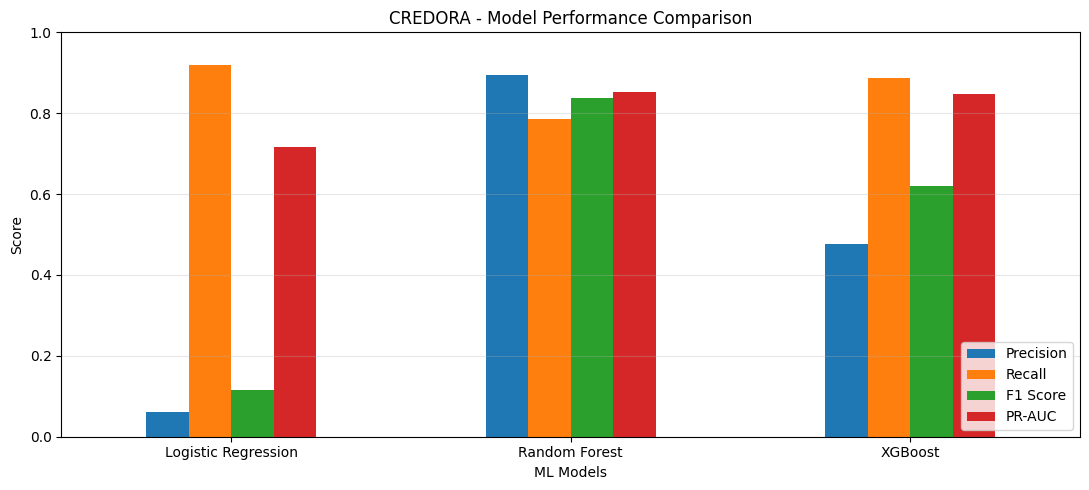

In [ ]:

# CREDORA | MODEL PERFORMANCE VISUALISATION

metrics = ["Precision", "Recall", "F1 Score", "PR-AUC"]

comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("CREDORA - Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("ML Models")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [ ]:

# ==========================================================
# CREDORA | RISK SCORING ENGINE
# ==========================================================

import numpy as np
import pandas as pd

# Use Random Forest probability predictions
risk_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

# Convert probability into a 0-100 score
risk_scores = np.round(risk_probabilities * 100, 2)

# Assign risk categories
def assign_risk_level(score):

    if score < 30:
        return "LOW"

    elif score < 70:
        return "MEDIUM"

    else:
        return "HIGH"

risk_levels = [
    assign_risk_level(score)
    for score in risk_scores
]

# Create CREDORA risk report
risk_report = pd.DataFrame({
    "Actual_Class": y_test.to_numpy(),
    "Fraud_Probability": risk_probabilities,
    "Risk_Score": risk_scores,
    "Risk_Level": risk_levels
})

print("========== CREDORA RISK REPORT ==========")

display(risk_report.head(15))

print("\nRisk Category Distribution:")
print(risk_report["Risk_Level"].value_counts())

print("\nRisk Scoring Engine Created Successfully!")


========== CREDORA RISK REPORT ==========


,Actual_Class,Fraud_Probability,Risk_Score,Risk_Level
0,0,0.000028,0.00,LOW
1,0,0.006899,0.69,LOW
2,0,0.013332,1.33,LOW
3,0,0.000028,0.00,LOW
4,0,0.019500,1.95,LOW
5,0,0.000028,0.00,LOW
6,0,0.000028,0.00,LOW
7,0,0.000028,0.00,LOW
8,0,0.000000,0.00,LOW
9,0,0.000245,0.02,LOW



Risk Category Distribution:
Risk_Level
LOW       56853
HIGH         75
MEDIUM       34
Name: count, dtype: int64

Risk Scoring Engine Created Successfully!


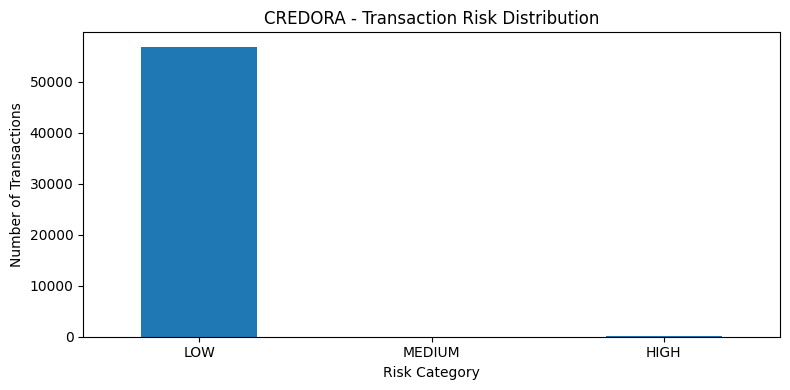

In [ ]:

# CREDORA | RISK DISTRIBUTION

risk_report["Risk_Level"].value_counts().reindex(
    ["LOW", "MEDIUM", "HIGH"],
    fill_value=0
).plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("CREDORA - Transaction Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Training validation model...

========== THRESHOLD RESULTS ==========
Optimal threshold: 0.61
Validation Precision: 0.8841
Validation Recall: 0.7722
Validation F1: 0.8243


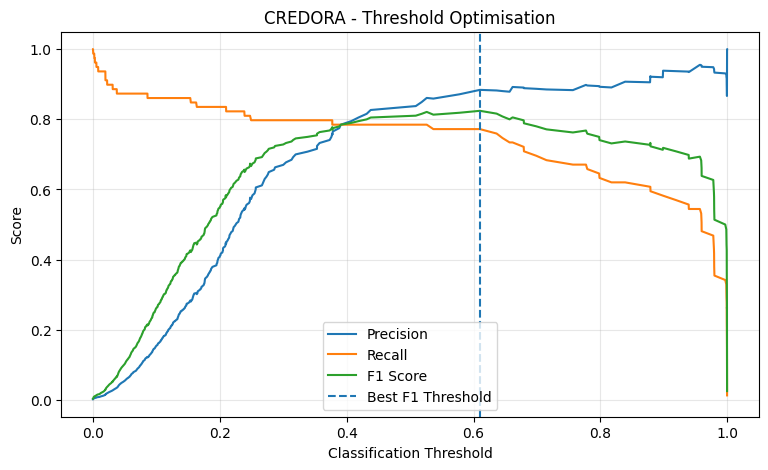

In [ ]:

# ==========================================================
# CREDORA | FRAUD THRESHOLD OPTIMISATION
# ==========================================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    average_precision_score
)
import numpy as np

# 1. Create a validation split from training data
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# 2. Train a validation model
validation_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Training validation model...")

validation_model.fit(X_subtrain, y_subtrain)

# 3. Get fraud probabilities on validation data
val_probabilities = validation_model.predict_proba(X_val)[:, 1]

# 4. Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

# 5. Calculate F1 for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("\n========== THRESHOLD RESULTS ==========")

print("Optimal threshold:", round(best_threshold, 4))
print("Validation Precision:", round(precision[best_index], 4))
print("Validation Recall:", round(recall[best_index], 4))
print("Validation F1:", round(f1_scores[best_index], 4))

# 6. Plot threshold performance
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1 Score")

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Best F1 Threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("CREDORA - Threshold Optimisation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# ==========================================================
# CREDORA | VALIDATION MODEL EVALUATION
# ==========================================================

val_predictions = (
    val_probabilities >= best_threshold
).astype(int)

print("Optimised Threshold:", round(best_threshold, 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_predictions,
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_predictions))

print("\nValidation PR-AUC:",
      round(average_precision_score(y_val, val_probabilities), 4))


Optimised Threshold: 0.61

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9998    0.9997     45490
           1     0.8841    0.7722    0.8243        79

    accuracy                         0.9994     45569
   macro avg     0.9418    0.8860    0.9120     45569
weighted avg     0.9994    0.9994    0.9994     45569


Confusion Matrix:
[[45482     8]
 [   18    61]]

Validation PR-AUC: 0.7728


In [ ]:

!pip install -q shap


Generating SHAP explanations...
SHAP explanations generated successfully!

Generating SHAP feature importance plot...


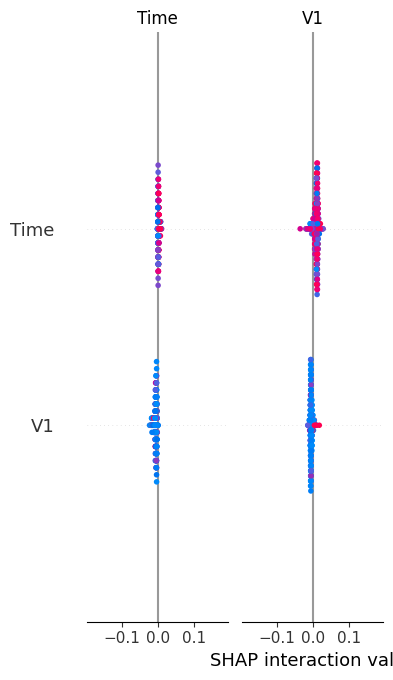

In [ ]:

# ==========================================================
# CREDORA | EXPLAINABLE AI - SHAP
# ==========================================================

import shap
import numpy as np
import pandas as pd

# Explain the validation Random Forest model
explainer = shap.TreeExplainer(validation_model)

# Select a small sample for faster explanation
sample_size = min(300, len(X_val))
X_explain = X_val[:sample_size]

print("Generating SHAP explanations...")

shap_values = explainer.shap_values(X_explain)

print("SHAP explanations generated successfully!")

# Display global feature importance
print("\nGenerating SHAP feature importance plot...")

shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=X.columns.tolist(),
    show=True
)


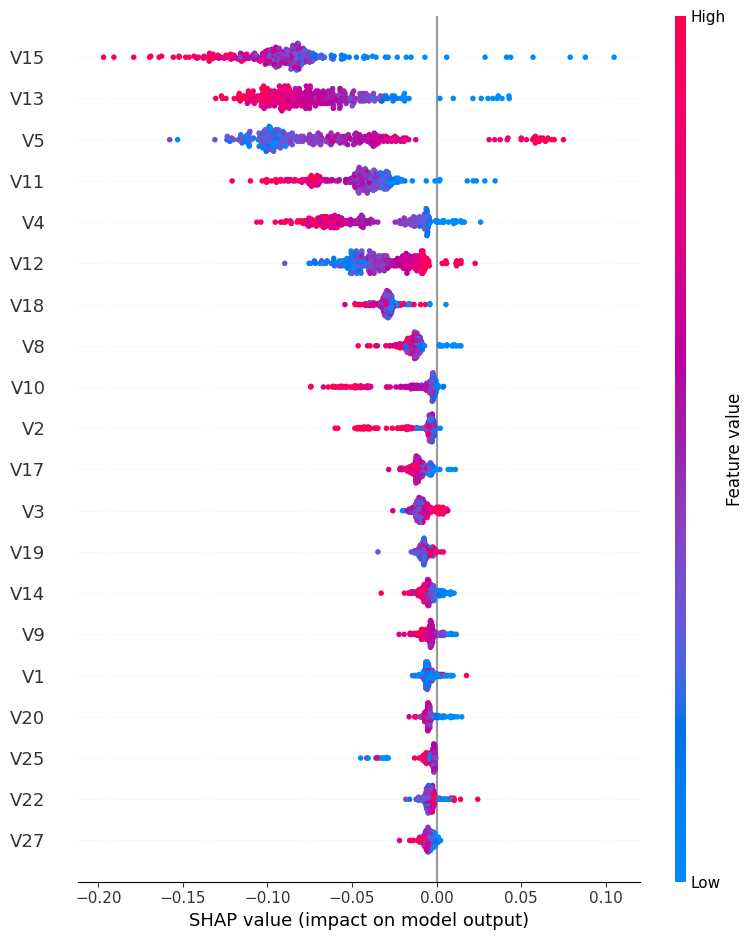

TOP 15 IMPORTANT FEATURES


,Feature,Mean_SHAP_Importance
15,V15,0.093483
13,V13,0.074034
5,V5,0.074006
11,V11,0.047309
4,V4,0.041808
12,V12,0.031954
18,V18,0.029245
8,V8,0.014229
10,V10,0.012929
2,V2,0.010247


In [ ]:

# ==========================================================
# CREDORA | CORRECT SHAP FEATURE IMPORTANCE
# ==========================================================

import numpy as np
import shap

# Extract SHAP values for the fraud class
if isinstance(shap_values, list):
    fraud_shap = shap_values[1]
elif len(shap_values.shape) == 3:
    fraud_shap = shap_values[:, :, 1]
else:
    fraud_shap = shap_values

# Generate complete feature importance
shap.summary_plot(
    fraud_shap,
    X_explain,
    feature_names=X.columns.tolist(),
    max_display=20,
    plot_type="dot"
)

# Calculate mean absolute SHAP importance
importance = np.abs(fraud_shap).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean_SHAP_Importance": importance
}).sort_values(
    by="Mean_SHAP_Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
display(shap_importance.head(15))


Transaction fraud probability: 0.26 %


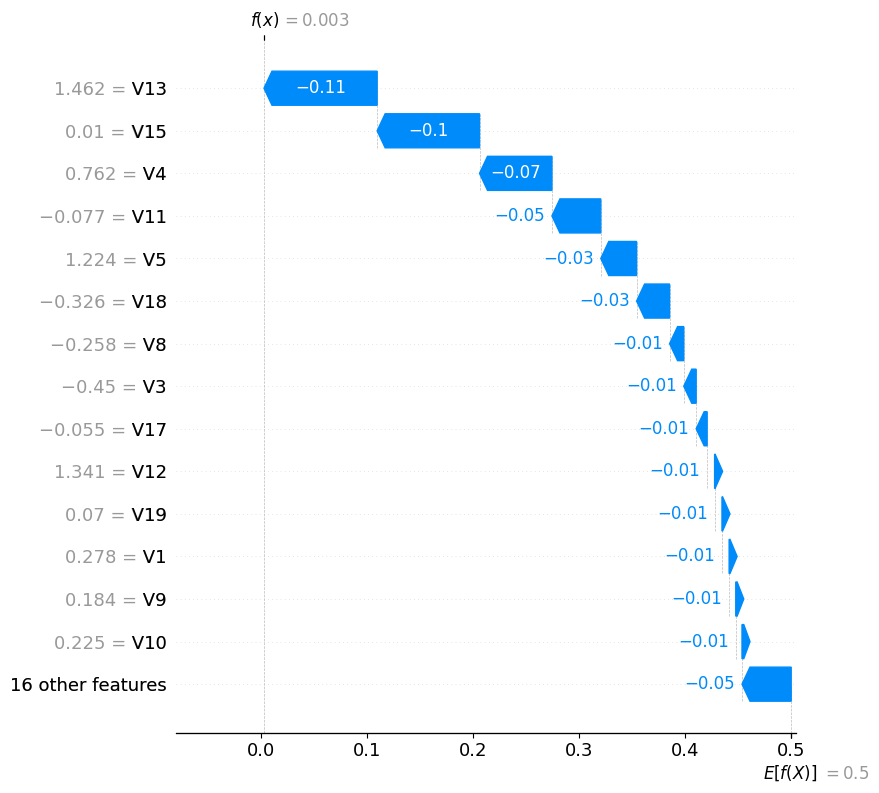

In [ ]:

# ==========================================================
# CREDORA | INDIVIDUAL TRANSACTION EXPLANATION
# ==========================================================

transaction_index = 0

transaction = X_explain[transaction_index]

print("Transaction fraud probability:",
      round(
          validation_model.predict_proba(
              transaction.reshape(1, -1)
          )[0][1] * 100, 2
      ), "%")

shap.waterfall_plot(
    shap.Explanation(
        values=fraud_shap[transaction_index],
        base_values=(
            explainer.expected_value[1]
            if isinstance(explainer.expected_value, (list, np.ndarray))
            else explainer.expected_value
        ),
        data=transaction,
        feature_names=X.columns.tolist()
    ),
    max_display=15
)


In [ ]:

# ==========================================================
# CREDORA | FINAL MODEL TRAINING
# ==========================================================

from sklearn.ensemble import RandomForestClassifier
import time

final_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Training final CREDORA fraud detection model...")

start = time.time()

final_model.fit(X_train_processed, y_train)

print("\nFINAL MODEL TRAINED SUCCESSFULLY!")
print("Training time:", round(time.time() - start, 2), "seconds")

print("Training records:", len(X_train_processed))
print("Testing records reserved:", len(X_test_processed))
print("Selected threshold:", round(best_threshold, 4))


Training final CREDORA fraud detection model...

FINAL MODEL TRAINED SUCCESSFULLY!
Training time: 84.23 seconds
Training records: 227845
Testing records reserved: 56962
Selected threshold: 0.61


In [ ]:

# ==========================================================
# CREDORA | FINAL MODEL TEST EVALUATION
# ==========================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

final_probabilities = final_model.predict_proba(
    X_test_processed
)[:, 1]

final_predictions = (
    final_probabilities >= best_threshold
).astype(int)

print("FINAL CREDORA MODEL REPORT")

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    digits=4
))

print("ROC-AUC:",
      round(roc_auc_score(y_test, final_probabilities), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, final_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))


FINAL CREDORA MODEL REPORT

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9997    0.9997     56864
           1     0.8298    0.7959    0.8125        98

    accuracy                         0.9994     56962
   macro avg     0.9147    0.8978    0.9061     56962
weighted avg     0.9994    0.9994    0.9994     56962

ROC-AUC: 0.9708
PR-AUC: 0.8274

Confusion Matrix:
[[56848    16]
 [   20    78]]


In [ ]:

# ==========================================================
# CREDORA | EXPORT MODEL PACKAGE
# ==========================================================

import joblib
import os

os.makedirs("/content/credora_models", exist_ok=True)

model_package = {
    "model": final_model,
    "preprocessor": preprocessor,
    "threshold": float(best_threshold),
    "features": X.columns.tolist(),
    "risk_categories": {
        "low": [0, 29],
        "medium": [30, 69],
        "high": [70, 100]
    },
    "model_name": "CREDORA Random Forest",
    "dataset": "ULB Credit Card Fraud"
}

model_path = "/content/credora_models/credora_ulb_model.joblib"

joblib.dump(model_package, model_path)

print("MODEL PACKAGE SAVED!")
print("Location:", model_path)
print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

# Download to your computer
from google.colab import files
files.download(model_path)


MODEL PACKAGE SAVED!
Location: /content/credora_models/credora_ulb_model.joblib
Model size: 0.78 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ==========================================================
# CREDORA | SPARKOV DATASET PREPARATION
# ==========================================================

import pandas as pd
import numpy as np

# Work on a copy of the original dataset
sparkov_processed = sparkov.copy()

print("Original dataset shape:", sparkov_processed.shape)

# 1. Convert transaction timestamp
sparkov_processed["trans_date_trans_time"] = pd.to_datetime(
    sparkov_processed["trans_date_trans_time"],
    errors="coerce"
)

# 2. Extract useful time-based features
sparkov_processed["transaction_hour"] = (
    sparkov_processed["trans_date_trans_time"].dt.hour
)

sparkov_processed["transaction_day"] = (
    sparkov_processed["trans_date_trans_time"].dt.day
)

sparkov_processed["transaction_month"] = (
    sparkov_processed["trans_date_trans_time"].dt.month
)

sparkov_processed["transaction_weekday"] = (
    sparkov_processed["trans_date_trans_time"].dt.dayofweek
)

# 3. Create transaction location distance
# Haversine distance between customer and merchant coordinates

lat1 = np.radians(sparkov_processed["lat"])
lon1 = np.radians(sparkov_processed["long"])

lat2 = np.radians(sparkov_processed["merch_lat"])
lon2 = np.radians(sparkov_processed["merch_long"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

sparkov_processed["merchant_distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a))
)

# 4. Display engineered features
print("\nNew features created:")
print([
    "transaction_hour",
    "transaction_day",
    "transaction_month",
    "transaction_weekday",
    "merchant_distance_km"
])

print("\nProcessed dataset shape:", sparkov_processed.shape)

display(sparkov_processed.head())


Original dataset shape: (1296675, 23)

New features created:
['transaction_hour', 'transaction_day', 'transaction_month', 'transaction_weekday', 'merchant_distance_km']

Processed dataset shape: (1296675, 28)


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,trans_num,unix_time,merch_lat,merch_long,is_fraud,transaction_hour,transaction_day,transaction_month,transaction_weekday,merchant_distance_km
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,0,1,1,1,78.597568
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,0,1,1,1,30.212176
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,0,1,1,1,108.206083
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,0,1,1,1,95.673231
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,0,1,1,1,77.556744


In [ ]:

# ==========================================================
# CREDORA | SPARKOV FEATURE INSPECTION
# ==========================================================

print("Missing values in engineered features:")

engineered_columns = [
    "transaction_hour",
    "transaction_day",
    "transaction_month",
    "transaction_weekday",
    "merchant_distance_km"
]

display(
    sparkov_processed[engineered_columns].isnull().sum()
)

print("\nTransaction amount statistics:")
display(sparkov_processed["amt"].describe())

print("\nMerchant distance statistics:")
display(sparkov_processed["merchant_distance_km"].describe())

print("\nFraud distribution:")
print(sparkov_processed["is_fraud"].value_counts())

print("\nSPARKOV FEATURE ENGINEERING COMPLETED!")


Missing values in engineered features:


,0
transaction_hour,0
transaction_day,0
transaction_month,0
transaction_weekday,0
merchant_distance_km,0



Transaction amount statistics:


,amt
count,1.296675e+06
mean,7.035104e+01
std,1.603160e+02
min,1.000000e+00
25%,9.650000e+00
50%,4.752000e+01
75%,8.314000e+01
max,2.894890e+04



Merchant distance statistics:


,merchant_distance_km
count,1.296675e+06
mean,7.611465e+01
std,2.911693e+01
min,2.225452e-02
25%,5.533491e+01
50%,7.823175e+01
75%,9.850327e+01
max,1.521172e+02



Fraud distribution:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

SPARKOV FEATURE ENGINEERING COMPLETED!


In [ ]:

# ==========================================================
# CREDORA | SPARKOV PREPROCESSING PIPELINE
# ==========================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# 1. Select useful features
numeric_features = [
    "amt",
    "city_pop",
    "transaction_hour",
    "transaction_day",
    "transaction_month",
    "transaction_weekday",
    "merchant_distance_km"
]

categorical_features = [
    "category",
    "gender",
    "state"
]

# 2. Keep only selected features
feature_columns = numeric_features + categorical_features

X_sparkov = sparkov_processed[feature_columns].copy()
y_sparkov = sparkov_processed["is_fraud"].astype(int)

# 3. Split data before preprocessing
X_sp_train, X_sp_test, y_sp_train, y_sp_test = train_test_split(
    X_sparkov,
    y_sparkov,
    test_size=0.20,
    random_state=42,
    stratify=y_sparkov
)

# 4. Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 5. Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=100
    ))
])

# 6. Combine preprocessing
sparkov_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 7. Fit only on training data
X_sp_train_processed = sparkov_preprocessor.fit_transform(X_sp_train)
X_sp_test_processed = sparkov_preprocessor.transform(X_sp_test)

print("========== SPARKOV PREPROCESSING REPORT ==========")
print("Training records:", X_sp_train_processed.shape[0])
print("Testing records:", X_sp_test_processed.shape[0])
print("Processed training features:", X_sp_train_processed.shape[1])
print("Processed testing features:", X_sp_test_processed.shape[1])

print("\nTraining fraud records:", int(y_sp_train.sum()))
print("Testing fraud records:", int(y_sp_test.sum()))

print("\nSPARKOV PREPROCESSING COMPLETED!")


========== SPARKOV PREPROCESSING REPORT ==========
Training records: 1037340
Testing records: 259335
Processed training features: 74
Processed testing features: 74

Training fraud records: 6005
Testing fraud records: 1501

SPARKOV PREPROCESSING COMPLETED!


In [ ]:

# ==========================================================
# CREDORA | SPARKOV XGBOOST MODEL
# ==========================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import time

negative = int((y_sp_train == 0).sum())
positive = int((y_sp_train == 1).sum())

sparkov_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=negative / positive,
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2
)

print("Training CREDORA Sparkov model...")

start = time.time()

sparkov_model.fit(X_sp_train_processed, y_sp_train)

print("Training completed!")
print("Time taken:", round(time.time() - start, 2), "seconds")

# Predictions
sparkov_prob = sparkov_model.predict_proba(
    X_sp_test_processed
)[:, 1]

sparkov_pred = (sparkov_prob >= 0.5).astype(int)

print("\n========== SPARKOV MODEL PERFORMANCE ==========")

print(classification_report(
    y_sp_test,
    sparkov_pred,
    digits=4
))

print("ROC-AUC:", round(
    roc_auc_score(y_sp_test, sparkov_prob), 4
))

print("PR-AUC:", round(
    average_precision_score(y_sp_test, sparkov_prob), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_sp_test, sparkov_pred))


Training CREDORA Sparkov model...
Training completed!
Time taken: 17.11 seconds

========== SPARKOV MODEL PERFORMANCE ==========
              precision    recall  f1-score   support

           0     0.9998    0.9741    0.9868    257834
           1     0.1784    0.9647    0.3012      1501

    accuracy                         0.9741    259335
   macro avg     0.5891    0.9694    0.6440    259335
weighted avg     0.9950    0.9741    0.9828    259335

ROC-AUC: 0.9958
PR-AUC: 0.7809

Confusion Matrix:
[[251167   6667]
 [    53   1448]]


In [ ]:

# ==========================================================
# CREDORA | SPARKOV MODEL EXPORT
# ==========================================================

import os
import joblib

os.makedirs("/content/credora_models", exist_ok=True)

sparkov_package = {
    "model": sparkov_model,
    "preprocessor": sparkov_preprocessor,
    "threshold": 0.5,
    "features": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "model_name": "CREDORA Sparkov XGBoost",
    "dataset": "Sparkov Fraud Detection"
}

sparkov_path = (
    "/content/credora_models/credora_sparkov_model.joblib"
)

joblib.dump(sparkov_package, sparkov_path)

print("SPARKOV MODEL SAVED SUCCESSFULLY!")
print("File size:",
      round(os.path.getsize(sparkov_path) / (1024 * 1024), 2),
      "MB")

from google.colab import files
files.download(sparkov_path)


SPARKOV MODEL SAVED SUCCESSFULLY!
File size: 0.17 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ==========================================================
# CREDORA | MERCHANT FRAUD ANALYTICS
# ==========================================================

merchant_analysis = (
    sparkov_processed
    .groupby("merchant")
    .agg(
        total_transactions=("is_fraud", "count"),
        fraud_transactions=("is_fraud", "sum"),
        total_amount=("amt", "sum")
    )
)

merchant_analysis["fraud_rate"] = (
    merchant_analysis["fraud_transactions"]
    / merchant_analysis["total_transactions"] * 100
)

merchant_analysis = merchant_analysis.sort_values(
    "fraud_transactions",
    ascending=False
)

print("TOP 15 MERCHANTS BY FRAUD COUNT")

display(merchant_analysis.head(15).round(2))

print("\nMERCHANT CATEGORY ANALYSIS")

category_analysis = (
    sparkov_processed
    .groupby("category")
    .agg(
        total_transactions=("is_fraud", "count"),
        fraud_transactions=("is_fraud", "sum")
    )
)

category_analysis["fraud_rate"] = (
    category_analysis["fraud_transactions"]
    / category_analysis["total_transactions"] * 100
)

display(
    category_analysis.sort_values(
        "fraud_rate", ascending=False
    ).round(3)
)

print("\nCREDORA MERCHANT ANALYTICS COMPLETED!")


TOP 15 MERCHANTS BY FRAUD COUNT


,total_transactions,fraud_transactions,total_amount,fraud_rate
merchant,,,,
fraud_Rau and Sons,2490,49,298354.77,1.97
fraud_Kozey-Boehm,1866,48,183312.29,2.57
fraud_Cormier LLC,3649,48,265129.92,1.32
fraud_Vandervort-Funk,2474,47,292542.99,1.90
fraud_Doyle Ltd,2558,47,300971.37,1.84
fraud_Kilback LLC,4403,47,391078.15,1.07
fraud_Kuhn LLC,3510,44,282207.15,1.25
fraud_Padberg-Welch,2424,44,279775.98,1.82
fraud_Terry-Huel,1996,43,186191.02,2.15



MERCHANT CATEGORY ANALYSIS


,total_transactions,fraud_transactions,fraud_rate
category,,,
shopping_net,97543,1713,1.756
misc_net,63287,915,1.446
grocery_pos,123638,1743,1.410
shopping_pos,116672,843,0.723
gas_transport,131659,618,0.469
misc_pos,79655,250,0.314
grocery_net,45452,134,0.295
travel,40507,116,0.286
entertainment,94014,233,0.248



CREDORA MERCHANT ANALYTICS COMPLETED!


STATE-WISE FRAUD ANALYSIS


,total_transactions,fraud_transactions,average_amount,fraud_rate
state,,,,
NY,83501,555,71.933,0.665
TX,94876,479,71.682,0.505
PA,79847,458,72.276,0.574
CA,56360,326,73.422,0.578
OH,46480,321,73.067,0.691
FL,42671,281,73.942,0.659
IL,43252,248,69.636,0.573
MI,46154,238,71.125,0.516
AL,40989,215,65.450,0.525


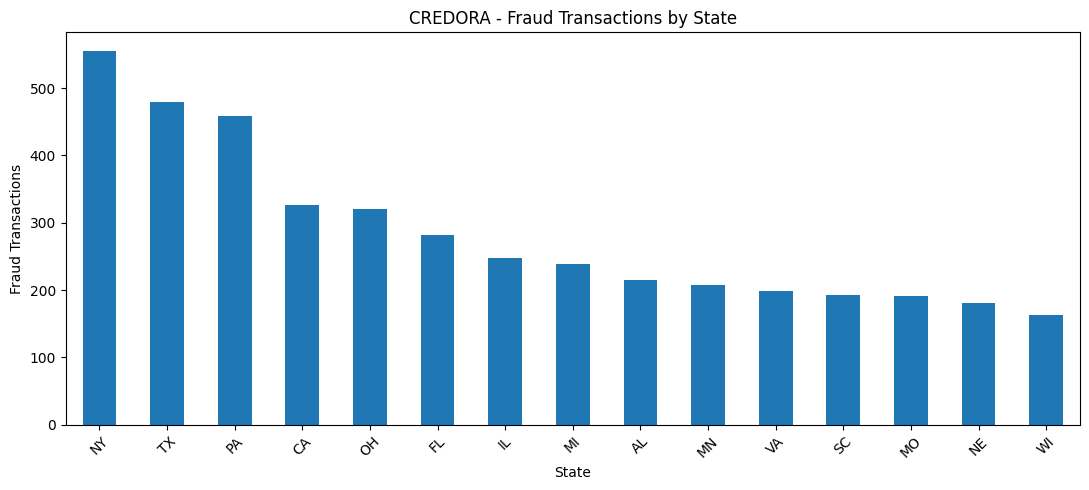

In [ ]:

# ==========================================================
# CREDORA | GEOGRAPHIC FRAUD ANALYTICS
# ==========================================================

state_analysis = (
    sparkov_processed
    .groupby("state")
    .agg(
        total_transactions=("is_fraud", "count"),
        fraud_transactions=("is_fraud", "sum"),
        average_amount=("amt", "mean")
    )
)

state_analysis["fraud_rate"] = (
    state_analysis["fraud_transactions"]
    / state_analysis["total_transactions"] * 100
)

print("STATE-WISE FRAUD ANALYSIS")

display(
    state_analysis.sort_values(
        "fraud_transactions",
        ascending=False
    ).head(20).round(3)
)

# Visualise transaction counts by state
state_analysis["fraud_transactions"].sort_values(
    ascending=False
).head(15).plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("CREDORA - Fraud Transactions by State")
plt.xlabel("State")
plt.ylabel("Fraud Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# ==========================================================
# CREDORA | PAYSIM DATASET PREPARATION
# ==========================================================

import pandas as pd
import numpy as np

paysim_processed = paysim.copy()

print("Original dataset shape:", paysim_processed.shape)

print("\nAvailable columns:")
print(paysim_processed.columns.tolist())

print("\nTransaction types:")
print(paysim_processed["type"].value_counts())

print("\nFraud distribution:")
print(paysim_processed["isFraud"].value_counts())

print("\nFirst five records:")
display(paysim_processed.head())


Original dataset shape: (6362620, 11)

Available columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Transaction types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Fraud distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

First five records:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:

# ==========================================================
# CREDORA | PAYSIM FEATURE ENGINEERING
# ==========================================================

# Balance changes
paysim_processed["origin_balance_change"] = (
    paysim_processed["oldbalanceOrg"]
    - paysim_processed["newbalanceOrig"]
)

paysim_processed["destination_balance_change"] = (
    paysim_processed["newbalanceDest"]
    - paysim_processed["oldbalanceDest"]
)

# Difference between transaction amount and origin balance change
paysim_processed["origin_error"] = (
    paysim_processed["origin_balance_change"]
    - paysim_processed["amount"]
)

# Difference between destination balance change and amount
paysim_processed["destination_error"] = (
    paysim_processed["destination_balance_change"]
    - paysim_processed["amount"]
)

# Transaction time features
paysim_processed["hour"] = paysim_processed["step"] % 24

print("New features created!")

display(paysim_processed.head())

print("\nFeature engineering completed!")


New features created!


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,origin_balance_change,destination_balance_change,origin_error,destination_error,hour
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0,1.455192e-11,-9839.64,1
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0,-1.136868e-12,-1864.28,1
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0,0.000000e+00,-181.00,1
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0,0.000000e+00,-21363.00,1
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0,0.000000e+00,-11668.14,1



Feature engineering completed!


In [ ]:

# ==========================================================
# CREDORA | PAYSIM PREPROCESSING
# ==========================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "origin_balance_change",
    "destination_balance_change",
    "origin_error",
    "destination_error",
    "hour"
]

categorical_features = ["type"]

X_paysim = paysim_processed[
    numeric_features + categorical_features
].copy()

y_paysim = paysim_processed["isFraud"].astype(int)

X_ps_train, X_ps_test, y_ps_train, y_ps_test = train_test_split(
    X_paysim,
    y_paysim,
    test_size=0.20,
    random_state=42,
    stratify=y_paysim
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

paysim_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_ps_train_processed = paysim_preprocessor.fit_transform(X_ps_train)
X_ps_test_processed = paysim_preprocessor.transform(X_ps_test)

print("Training records:", X_ps_train_processed.shape[0])
print("Testing records:", X_ps_test_processed.shape[0])
print("Training fraud records:", int(y_ps_train.sum()))
print("Testing fraud records:", int(y_ps_test.sum()))

print("\nPAYSIM PREPROCESSING COMPLETED!")


Training records: 5090096
Testing records: 1272524
Training fraud records: 6570
Testing fraud records: 1643

PAYSIM PREPROCESSING COMPLETED!


In [ ]:

# ==========================================================
# CREDORA | PAYSIM XGBOOST MODEL
# ==========================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import time

negative = int((y_ps_train == 0).sum())
positive = int((y_ps_train == 1).sum())

paysim_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=negative / positive,
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2
)

print("Training CREDORA PaySim model...")

start = time.time()

paysim_model.fit(X_ps_train_processed, y_ps_train)

print("Training completed!")
print("Time taken:", round(time.time() - start, 2), "seconds")

paysim_prob = paysim_model.predict_proba(
    X_ps_test_processed
)[:, 1]

paysim_pred = (paysim_prob >= 0.5).astype(int)

print("\n========== PAYSIM MODEL PERFORMANCE ==========")

print(classification_report(
    y_ps_test,
    paysim_pred,
    digits=4
))

print("ROC-AUC:", round(
    roc_auc_score(y_ps_test, paysim_prob), 4
))

print("PR-AUC:", round(
    average_precision_score(y_ps_test, paysim_prob), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_ps_test, paysim_pred))


Training CREDORA PaySim model...
Training completed!
Time taken: 68.48 seconds

========== PAYSIM MODEL PERFORMANCE ==========
              precision    recall  f1-score   support

           0     1.0000    0.9999    0.9999   1270881
           1     0.9016    0.9988    0.9477      1643

    accuracy                         0.9999   1272524
   macro avg     0.9508    0.9993    0.9738   1272524
weighted avg     0.9999    0.9999    0.9999   1272524

ROC-AUC: 0.9999
PR-AUC: 0.9987

Confusion Matrix:
[[1270702     179]
 [      2    1641]]


In [ ]:
import os
import joblib

os.makedirs("/content/credora_models", exist_ok=True)

paysim_package = {
    "model": paysim_model,
    "preprocessor": paysim_preprocessor,
    "threshold": 0.5,
    "features": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "model_name": "CREDORA PaySim XGBoost",
    "dataset": "PaySim Synthetic Transactions"
}

joblib.dump(
    paysim_package,
    "/content/credora_models/credora_paysim_model.joblib"
)

print("PaySim model saved successfully!")

PaySim model saved successfully!


In [ ]:
from google.colab import files

files.download("/content/credora_models/credora_paysim_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np

# Create a small transaction stream from PaySim
stream_size = 100

live_transactions = paysim.sample(
    n=stream_size,
    random_state=42
).reset_index(drop=True)

print("Simulated transaction stream created!")
print("Total transactions:", len(live_transactions))

display(live_transactions.head(10))

Simulated transaction stream created!
Total transactions: 100


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,278,CASH_IN,330218.42,C632336343,20866.00,351084.42,C834976624,452419.57,122201.15,0,0
1,15,PAYMENT,11647.08,C1264712553,30370.00,18722.92,M215391829,0.00,0.00,0,0
2,10,CASH_IN,152264.21,C1746846248,106589.00,258853.21,C1607284477,201303.01,49038.80,0,0
3,403,TRANSFER,1551760.63,C333676753,0.00,0.00,C1564353608,3198359.45,4750120.08,0,0
4,206,CASH_IN,78172.30,C813403091,2921331.58,2999503.88,C1091768874,415821.90,337649.60,0,0
5,259,PAYMENT,915.13,C2002954533,0.00,0.00,M290849763,0.00,0.00,0,0
6,188,CASH_OUT,20603.87,C813757373,0.00,0.00,C823291717,558068.66,578672.53,0,0
7,139,CASH_OUT,58605.72,C1850864812,0.00,0.00,C618657299,585494.94,644100.66,0,0
8,230,PAYMENT,4865.11,C886849972,0.00,0.00,M623175144,0.00,0.00,0,0
9,544,CASH_OUT,118131.63,C390714641,0.00,0.00,C366360355,8131691.35,8476246.86,0,0


In [ ]:
# Recreate the features used during PaySim training
stream_processed = live_transactions.copy()

stream_processed["origin_balance_change"] = (
    stream_processed["oldbalanceOrg"] -
    stream_processed["newbalanceOrig"]
)

stream_processed["destination_balance_change"] = (
    stream_processed["newbalanceDest"] -
    stream_processed["oldbalanceDest"]
)

stream_processed["origin_error"] = (
    stream_processed["origin_balance_change"] -
    stream_processed["amount"]
)

stream_processed["destination_error"] = (
    stream_processed["destination_balance_change"] -
    stream_processed["amount"]
)

stream_processed["hour"] = stream_processed["step"] % 24

# Select exactly the features used during training
X_stream = stream_processed[
    numeric_features + categorical_features
]

# Transform and predict
X_stream_transformed = paysim_preprocessor.transform(X_stream)

stream_processed["fraud_probability"] = (
    paysim_model.predict_proba(X_stream_transformed)[:, 1]
)

stream_processed["risk_score"] = (
    stream_processed["fraud_probability"] * 100
).round(2)

stream_processed["predicted_fraud"] = (
    stream_processed["fraud_probability"] >= 0.5
).astype(int)

stream_processed["risk_level"] = np.where(
    stream_processed["risk_score"] >= 70, "HIGH",
    np.where(stream_processed["risk_score"] >= 30, "MEDIUM", "LOW")
)

print("CREDORA transaction analysis completed!")

CREDORA transaction analysis completed!


In [ ]:
display(
    stream_processed[
        [
            "type",
            "amount",
            "fraud_probability",
            "risk_score",
            "risk_level",
            "predicted_fraud",
            "isFraud"
        ]
    ].head(20)
)

print("\nMonitoring Summary")
print("------------------")
print("Transactions analysed:", len(stream_processed))
print("Predicted suspicious:", stream_processed["predicted_fraud"].sum())
print("High-risk transactions:", (stream_processed["risk_level"] == "HIGH").sum())
print("Actual fraud cases:", stream_processed["isFraud"].sum())

,type,amount,fraud_probability,risk_score,risk_level,predicted_fraud,isFraud
0,CASH_IN,330218.42,0.000925,0.09,LOW,0,0
1,PAYMENT,11647.08,0.000248,0.02,LOW,0,0
2,CASH_IN,152264.21,0.000839,0.08,LOW,0,0
3,TRANSFER,1551760.63,0.000778,0.08,LOW,0,0
4,CASH_IN,78172.30,0.000510,0.05,LOW,0,0
5,PAYMENT,915.13,0.000387,0.04,LOW,0,0
6,CASH_OUT,20603.87,0.003013,0.30,LOW,0,0
7,CASH_OUT,58605.72,0.003754,0.38,LOW,0,0
8,PAYMENT,4865.11,0.002444,0.24,LOW,0,0
9,CASH_OUT,118131.63,0.001300,0.13,LOW,0,0



Monitoring Summary
------------------
Transactions analysed: 100
Predicted suspicious: 0
High-risk transactions: 0
Actual fraud cases: 0


In [ ]:
# Generate alerts from simulated transaction results

alerts = stream_processed[
    (stream_processed["predicted_fraud"] == 1) |
    (stream_processed["risk_level"] == "HIGH")
].copy()

alerts = alerts.reset_index(drop=True)

alerts["alert_id"] = [
    f"CRD-{i+1:05d}" for i in range(len(alerts))
]

alerts["alert_status"] = "OPEN"

alerts["alert_priority"] = np.where(
    alerts["risk_score"] >= 70, "CRITICAL",
    np.where(alerts["risk_score"] >= 50, "HIGH", "MEDIUM")
)

alerts["alert_reason"] = np.where(
    alerts["fraud_probability"] >= 0.5,
    "ML model detected suspicious transaction patterns",
    "Transaction exceeded high-risk score threshold"
)

alert_columns = [
    "alert_id",
    "type",
    "amount",
    "fraud_probability",
    "risk_score",
    "risk_level",
    "alert_priority",
    "alert_reason",
    "alert_status"
]

print("CREDORA alert generation completed!")
print("Total alerts generated:", len(alerts))

display(alerts[alert_columns].head(20))

CREDORA alert generation completed!
Total alerts generated: 0


,alert_id,type,amount,fraud_probability,risk_score,risk_level,alert_priority,alert_reason,alert_status


In [ ]:
print("CREDORA ALERT ANALYTICS")
print("=======================")

print("\nAlerts by priority:")
display(alerts["alert_priority"].value_counts())

print("\nAlerts by status:")
display(alerts["alert_status"].value_counts())

print("\nTotal transaction amount under alert:")
print(round(alerts["amount"].sum(), 2))

print("\nAverage risk score:")
print(round(alerts["risk_score"].mean(), 2) if len(alerts) else 0)

CREDORA ALERT ANALYTICS

Alerts by priority:


,count
alert_priority,



Alerts by status:


,count
alert_status,



Total transaction amount under alert:
0.0

Average risk score:
0


In [ ]:
import os

os.makedirs("/content/credora_outputs", exist_ok=True)

# Export analysed transactions
stream_processed.to_csv(
    "/content/credora_outputs/analysed_transactions.csv",
    index=False
)

# Export generated alerts
alerts.to_csv(
    "/content/credora_outputs/fraud_alerts.csv",
    index=False
)

print("CREDORA output files created!")
print("1. analysed_transactions.csv")
print("2. fraud_alerts.csv")

CREDORA output files created!
1. analysed_transactions.csv
2. fraud_alerts.csv


In [ ]:
from google.colab import files

files.download("/content/credora_outputs/analysed_transactions.csv")
files.download("/content/credora_outputs/fraud_alerts.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

model_results = []

def add_model_result(name, y_true, y_pred, y_prob):
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob)
    })

print("Performance report function created!")

Performance report function created!


In [ ]:
print([
    name for name in globals()
    if "paysim" in name.lower()
])

['paysim', 'paysim_processed', 'X_paysim', 'y_paysim', 'paysim_preprocessor', 'paysim_model', 'paysim_prob', 'paysim_pred', 'paysim_package']


In [ ]:
print("FEATURE VARIABLES:")
print([name for name in globals() if name.startswith("X_")])

print("\nTARGET VARIABLES:")
print([name for name in globals() if name.startswith("y_")])

FEATURE VARIABLES:
['X_train', 'X_test', 'X_train_processed', 'X_test_processed', 'X_subtrain', 'X_val', 'X_explain', 'X_sparkov', 'X_sp_train', 'X_sp_test', 'X_sp_train_processed', 'X_sp_test_processed', 'X_paysim', 'X_ps_train', 'X_ps_test', 'X_ps_train_processed', 'X_ps_test_processed', 'X_stream', 'X_stream_transformed']

TARGET VARIABLES:
['y_train', 'y_test', 'y_pred', 'y_prob', 'y_subtrain', 'y_val', 'y_sparkov', 'y_sp_train', 'y_sp_test', 'y_paysim', 'y_ps_train', 'y_ps_test']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# ULB model
ulb_prob = final_model.predict_proba(X_test_processed)[:, 1]
ulb_pred = (ulb_prob >= best_threshold).astype(int)

add_model_result("ULB Random Forest", y_test, ulb_pred, ulb_prob)


# Sparkov model
sparkov_prob_report = sparkov_model.predict_proba(
    X_sp_test_processed
)[:, 1]

sparkov_pred_report = (sparkov_prob_report >= 0.5).astype(int)

add_model_result(
    "Sparkov XGBoost",
    y_sp_test,
    sparkov_pred_report,
    sparkov_prob_report
)


# PaySim model — corrected variable names
paysim_prob_report = paysim_model.predict_proba(
    X_ps_test_processed
)[:, 1]

paysim_pred_report = (paysim_prob_report >= 0.5).astype(int)

add_model_result(
    "PaySim XGBoost",
    y_ps_test,
    paysim_pred_report,
    paysim_prob_report
)

print("All three models added successfully!")

All three models added successfully!


In [ ]:
performance_report = pd.DataFrame(model_results)

display(
    performance_report.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

performance_report.to_csv(
    "/content/credora_outputs/model_performance_report.csv",
    index=False
)

print("Performance report exported successfully!")

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,ULB Random Forest,0.9994,0.8298,0.7959,0.8125,0.9708,0.8274
1,Sparkov XGBoost,0.9741,0.1784,0.9647,0.3012,0.9958,0.7809
2,ULB Random Forest,0.9994,0.8298,0.7959,0.8125,0.9708,0.8274
3,Sparkov XGBoost,0.9741,0.1784,0.9647,0.3012,0.9958,0.7809
4,PaySim XGBoost,0.9999,0.9016,0.9988,0.9477,0.9999,0.9987


Performance report exported successfully!


In [ ]:
from google.colab import files

files.download(
    "/content/credora_outputs/model_performance_report.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
ml_summary = {
    "project": "CREDORA",
    "title": "AI-Powered Credit Card Fraud Detection and Financial Transaction Monitoring System",
    "models": [
        {
            "name": "Random Forest",
            "dataset": "ULB Credit Card Fraud",
            "purpose": "Credit card fraud prediction"
        },
        {
            "name": "XGBoost",
            "dataset": "Sparkov Fraud Detection",
            "purpose": "Merchant, customer and geographic fraud analysis"
        },
        {
            "name": "XGBoost",
            "dataset": "PaySim",
            "purpose": "Synthetic transaction monitoring and fraud detection"
        }
    ],
    "features_completed": [
        "Data inspection",
        "Data preprocessing",
        "Model training",
        "Model evaluation",
        "Threshold selection for ULB",
        "Risk scoring",
        "SHAP explainability exploration",
        "Simulated transaction monitoring",
        "Automated fraud alert generation",
        "Model performance reporting"
    ],
    "next_phase": "FastAPI backend development"
}

import json

with open(
    "/content/credora_outputs/credora_ml_summary.json",
    "w"
) as f:
    json.dump(ml_summary, f, indent=4)

print("CREDORA ML summary created!")

CREDORA ML summary created!


In [ ]:
import os

report_path = "/content/credora_outputs/model_performance_report.csv"

print("File exists:", os.path.exists(report_path))

if os.path.exists(report_path):
    print("File size:", os.path.getsize(report_path), "bytes")
    display(pd.read_csv(report_path))

File exists: True
File size: 686 bytes


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,ULB Random Forest,0.999368,0.829787,0.795918,0.812500,0.970754,0.827356
1,Sparkov XGBoost,0.974088,0.178435,0.964690,0.301165,0.995805,0.780919
2,ULB Random Forest,0.999368,0.829787,0.795918,0.812500,0.970754,0.827356
3,Sparkov XGBoost,0.974088,0.178435,0.964690,0.301165,0.995805,0.780919
4,PaySim XGBoost,0.999858,0.901648,0.998783,0.947733,0.999928,0.998719


In [ ]:
from google.colab import files

files.download(report_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>